# 03. Model A: klasyczna sieć 1D-CNN

Cel: zbudować dobry model bazowy i dobrać jego hiperparametry **na zbiorze walidacyjnym**.
Wybrana konfiguracja (architektura, learning rate, wagi klas) przejdzie potem bez zmian do modelu B.
Zbioru testowego tu **nie używamy**.

1. Architektura
2. Pierwszy trening
3. Ocena na walidacji
4. Dobór hiperparametrów
5. Wybrana konfiguracja
6. Wnioski

Każdy trening jest logowany w `runs/<data>_<godzina>_<nazwa>/` (konfiguracja, historia, wagi, metryki, predykcje),
a zbiorcza tabela jest w `runs/index.csv`. Ponowne uruchomienie notebooka wczytuje gotowe przebiegi zamiast trenować od nowa.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

from src.data import CLASSES, ROOT
from src.evaluate import metrics, predictions_frame, reliability
from src.models import DEFAULT_CONFIG, build_model, predict_samples
from src.preprocessing import load_dataset
from src.runs import list_runs, run_or_load

sns.set_theme(style="whitegrid")
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

data = load_dataset()
y_train, y_val = data["train"]["y"], data["val"]["y"]

/opt/homebrew/Caskroom/miniconda/base/envs/prob-clf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Architektura

Cztery bloki **[konwolucja 1D → BatchNorm → ReLU → MaxPool]**, uśrednienie po czasie, warstwa gęsta z dropoutem
i warstwa wyjściowa z 5 logitami. Ta sama funkcja `build_model()` z `probabilistic=True` zbuduje model B
z warstwami Flipout w miejscu konwolucji i warstw gęstych.

In [2]:
pd.Series(DEFAULT_CONFIG, name="domyślna konfiguracja").to_frame()

,domyślna konfiguracja
filters,"(32, 64, 64, 128)"
kernel_size,7
dense_units,64
dropout,0.3
learning_rate,0.001
batch_size,64
epochs,60
patience,8
class_weight_power,1.0
kl_scale,1.0


In [3]:
build_model().summary()

Model: "model_A"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 1000, 12)]        0         


 conv1d (Conv1D)             (None, 1000, 32)          2720      


 batch_normalization (Batch  (None, 1000, 32)          128       


... (27 outputs left out)

Total params: 113061 (441.64 KB)


Trainable params: 112485 (439.39 KB)


Non-trainable params: 576 (2.25 KB)


_________________________________________________________________


## 2. Pierwszy trening

Domyślna konfiguracja, pełne wagi klas, early stopping na stracie walidacyjnej (cierpliwość 8 epok).

In [4]:
def run(name, **changes):
    return run_or_load(f"A_{name}", data, changes)

base = run("bazowy")
model = base.model
print(f"Przebieg: {base.run_id}")
print(f"Epok: {base.metrics['epochs']}, czas: {base.metrics['seconds'] / 60:.1f} min")

Przebieg: 2026-11-11_15-57-01_A_bazowy
Epok: 24, czas: 4.8 min


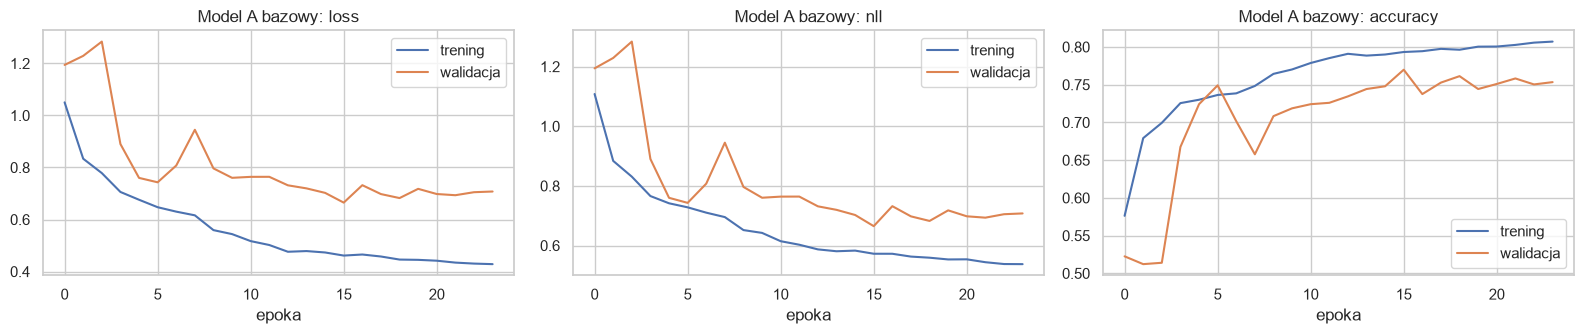

In [5]:
def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
    for key, ax in zip(["loss", "nll", "accuracy"], axes):
        ax.plot(history[key], label="trening")
        ax.plot(history[f"val_{key}"], label="walidacja")
        ax.set(title=f"{title} {key}", xlabel="epoka")
        ax.legend()
    plt.tight_layout()

plot_history(base.history, "Model A bazowy:")

Strata treningowa jest liczona z wagami klas, a walidacyjna bez wag, więc ich wartości nie są wprost porównywalne.
Liczy się kształt krzywych: czy walidacja przestaje się poprawiać i kiedy. Early stopping patrzy na walidacyjne `nll`
(w modelu A to to samo co `loss`, w modelu B strata zawiera dodatkowo składnik KL).

## 3. Ocena na walidacji

In [6]:
probs = predict_samples(model, data["val"]["X"])[0]
pd.Series(metrics(probs, y_val)).round(3).to_frame("model A bazowy")

,model A bazowy
accuracy,0.770
balanced_accuracy,0.687
macro_f1,0.683
nll,0.665
brier,0.341
ece,0.058
entropy,0.532


              precision    recall  f1-score   support

        NORM      0.875     0.829     0.851       916
          MI      0.635     0.624     0.629       234
        STTC      0.628     0.797     0.702       256
          CD      0.773     0.733     0.752       172
         HYP      0.509     0.453     0.479        64

    accuracy                          0.770      1642
   macro avg      0.684     0.687     0.683      1642
weighted avg      0.777     0.770     0.772      1642



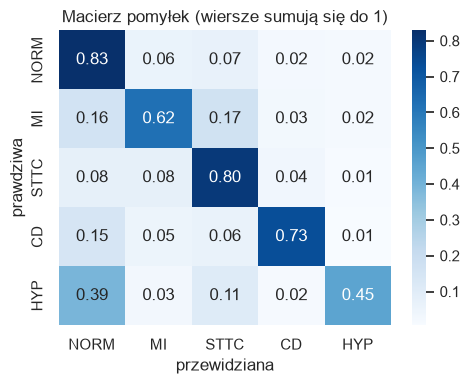

In [7]:
pred = probs.argmax(axis=1)
print(classification_report(y_val, pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_val, pred, normalize="true")
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("przewidziana")
plt.ylabel("prawdziwa")
plt.title("Macierz pomyłek (wiersze sumują się do 1)")
plt.tight_layout()

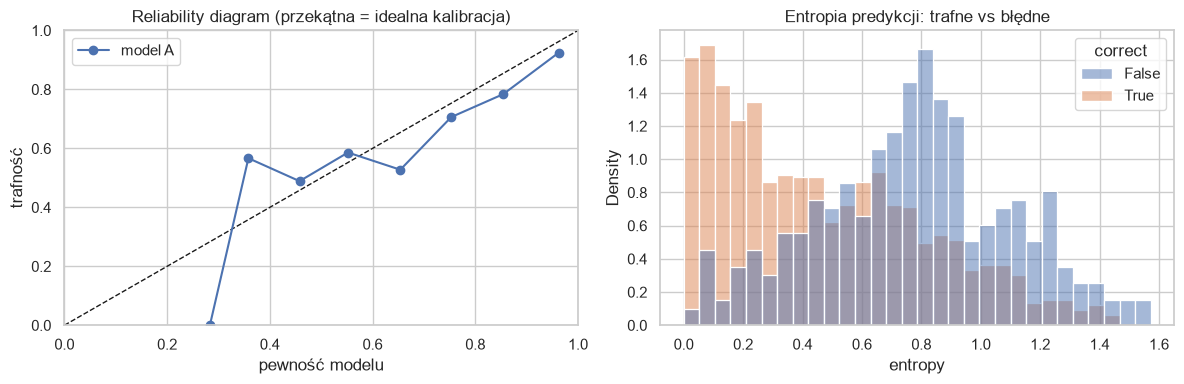

In [8]:
def plot_reliability(probs, y, ax, label):
    table = reliability(probs, y)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.plot(table["pewność"], table["trafność"], "o-", label=label)
    ax.set(xlabel="pewność modelu", ylabel="trafność", xlim=(0, 1), ylim=(0, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_reliability(probs, y_val, axes[0], "model A")
axes[0].set_title("Reliability diagram (przekątna = idealna kalibracja)")
axes[0].legend()

frame = predictions_frame(predict_samples(model, data["val"]["X"]), data["val"])
sns.histplot(data=frame, x="entropy", hue="correct", bins=30, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Entropia predykcji: trafne vs błędne")
plt.tight_layout()

## 4. Dobór hiperparametrów

Zmieniamy **jeden czynnik naraz** względem konfiguracji bazowej (7 treningów zamiast pełnej siatki):

| Czynnik | Warianty |
|---|---|
| wagi klas | brak (p=0), łagodne (p=0,5), pełne (p=1, bazowy) |
| dropout | 0, 0,3 (bazowy), 0,5 |
| rozmiar sieci | mała (16-32-32-64), bazowa (32-64-64-128), duża (64-128-128-256) |

**Kryterium wyboru: macro-F1 na walidacji**, bo wszystkie klasy są dla nas równie ważne.
NLL i ECE pokazujemy obok, żeby widzieć, jak wybór wpływa na kalibrację.

In [9]:
SEARCH = {
    "wagi klas": {"bazowy": {}, "wagi_brak": {"class_weight_power": 0.0},
                  "wagi_lagodne": {"class_weight_power": 0.5}},
    "dropout": {"bazowy": {}, "dropout_0": {"dropout": 0.0}, "dropout_05": {"dropout": 0.5}},
    "rozmiar sieci": {"bazowy": {}, "siec_mala": {"filters": (16, 32, 32, 64)},
                      "siec_duza": {"filters": (64, 128, 128, 256)}},
}

rows = []
for factor, variants in SEARCH.items():
    for name, changes in variants.items():
        r = run(name, **changes)
        rows.append({"czynnik": factor, "wariant": name, **r.metrics["val"], "epok": r.metrics["epochs"],
                     "minut": r.metrics["seconds"] / 60, "parametrów": r.metrics["parameters"], "run_id": r.run_id})

search = pd.DataFrame(rows).set_index(["czynnik", "wariant"])
search.round(3)

accuracy  balanced_accuracy  macro_f1    nll  \
czynnik       wariant                                                      
wagi klas     bazowy           0.770              0.687     0.683  0.665   
              wagi_brak        0.775              0.645     0.667  0.631   
              wagi_lagodne     0.783              0.673     0.684  0.606   
dropout       bazowy           0.770              0.687     0.683  0.665   
              dropout_0        0.770              0.667     0.672  0.650   
              dropout_05       0.779              0.691     0.685  0.637   
rozmiar sieci bazowy           0.770              0.687     0.683  0.665   
              siec_mala        0.762              0.682     0.665  0.662   
              siec_duza        0.773              0.694     0.686  0.666   

                            brier    ece  entropy  epok  minut  parametrów  \
czynnik       wariant                                                        
wagi klas     bazowy        0.341  0.058    0.532    24  4.804      113061   
              wagi_brak     0.325  0.051    0.480    16  2.932      113061   
              wagi_lagodne  0.312  0.045    0.479    18  3.269      113061   
dropout       bazowy        0.341  0.058    0.532    24  4.804      113061   
              dropout_0     0.333  0.067    0.448    22  4.048      113061   
              dropout_05    0.325  0.049    0.520    27  4.846      113061   
rozmiar sieci bazowy        0.341  0.058    0.532    24  4.804      113061   
              siec_mala     0.346  0.033    0.586    23  2.330       31637   
              siec_duza     0.331  0.078    0.422    27  9.726      426437   

                                                        run_id  
czynnik       wariant                                           
wagi klas     bazowy              2026-11-11_15-57-01_A_bazowy  
              wagi_brak        2026-11-11_15-59-59_A_wagi_brak  
              wagi_lagodne  2026-11-11_16-03-15_A_wagi_lagodne  
dropout       bazowy              2026-11-11_15-57-01_A_bazowy  
              dropout_0        2026-11-11_16-07-19_A_dropout_0  
              dropout_05      2026-11-11_16-12-11_A_dropout_05  
rozmiar sieci bazowy              2026-11-11_15-57-01_A_bazowy  
              siec_mala        2026-11-11_16-14-31_A_siec_mala  
              siec_duza        2026-11-11_16-24-16_A_siec_duza

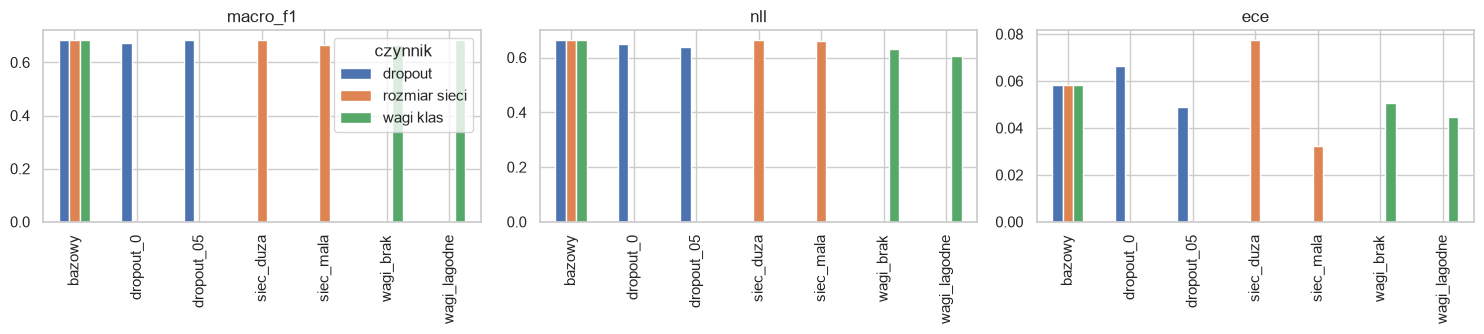

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, metric in zip(axes, ["macro_f1", "nll", "ece"]):
    search[metric].unstack(0).plot.bar(ax=ax, title=metric, legend=ax is axes[0])
    ax.set_xlabel("")
plt.tight_layout()

## 5. Wybrana konfiguracja

Dla każdego czynnika wybieramy wariant z najwyższym macro-F1 i łączymy wybory w jedną konfigurację.
Jeśli taka kombinacja nie była jeszcze trenowana, trenujemy ją teraz.

In [11]:
chosen = {}
for factor, variants in SEARCH.items():
    best = search.loc[factor, "macro_f1"].idxmax()
    print(f"{factor:15s} -> {best}")
    chosen.update(variants[best])

config_A = {**DEFAULT_CONFIG, **chosen}
pd.Series(config_A, name="wybrana konfiguracja").to_frame()

wagi klas       -> wagi_lagodne
dropout         -> dropout_05
rozmiar sieci   -> siec_duza


,wybrana konfiguracja
filters,"(64, 128, 128, 256)"
kernel_size,7
dense_units,64
dropout,0.5
learning_rate,0.001
batch_size,64
epochs,60
patience,8
class_weight_power,0.5
kl_scale,1.0


In [12]:
run_A = run("wybrany", **chosen)
print(f"Przebieg: {run_A.run_id}")
samples = predict_samples(run_A.model, data["val"]["X"])
probs_A = samples[0]
summary = pd.DataFrame({"bazowy": pd.Series(base.metrics["val"]), "wybrany": pd.Series(run_A.metrics["val"])})
summary.round(3)

Przebieg: 2026-11-11_16-30-50_A_wybrany


,bazowy,wybrany
accuracy,0.770,0.792
balanced_accuracy,0.687,0.647
macro_f1,0.683,0.684
nll,0.665,0.597
brier,0.341,0.302
ece,0.058,0.050
entropy,0.532,0.453


              precision    recall  f1-score   support

        NORM      0.825     0.917     0.869       916
          MI      0.719     0.568     0.635       234
        STTC      0.688     0.730     0.708       256
          CD      0.902     0.692     0.783       172
         HYP      0.600     0.328     0.424        64

    accuracy                          0.792      1642
   macro avg      0.747     0.647     0.684      1642
weighted avg      0.788     0.792     0.784      1642



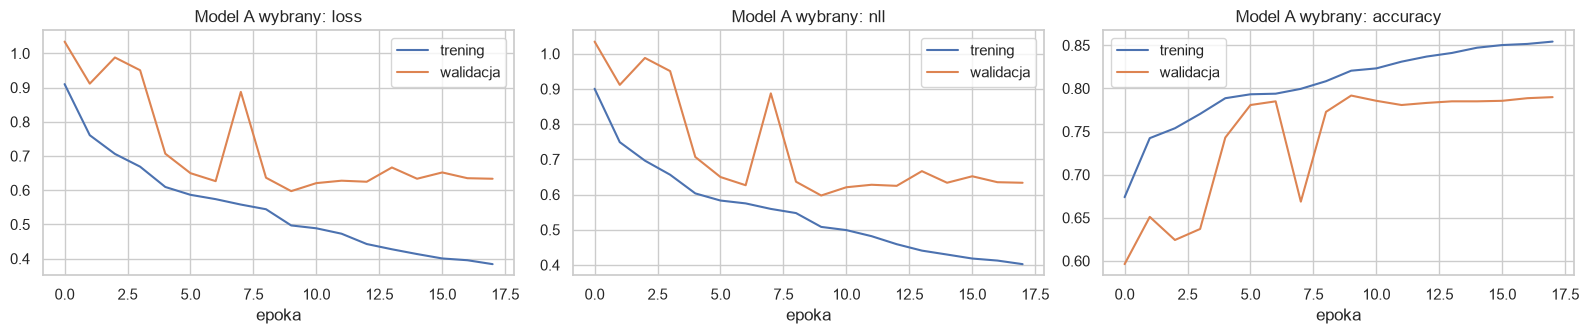

In [13]:
print(classification_report(y_val, probs_A.argmax(axis=1), target_names=CLASSES, digits=3))
plot_history(run_A.history, "Model A wybrany:")

### Zapowiedź głównej analizy: entropia a pewność diagnozy

Na razie tylko model A i tylko walidacja. Pełne porównanie z modelem B zrobimy na zbiorze testowym.

In [14]:
val_frame = predictions_frame(samples, data["val"])
subset = val_frame[val_frame.label.isin(["NORM", "MI"]) & val_frame.likelihood.notna()]
(subset.groupby(["label", "likelihood"]).entropy.agg(["mean", "count"]).round(3)
       .unstack(0).swaplevel(axis=1).sort_index(axis=1))

label         MI         NORM       
           count   mean count   mean
likelihood                          
15.0          61  0.617     9  0.652
35.0           8  0.850     4  0.608
50.0          39  0.610    54  0.548
80.0           8  0.746   153  0.448
100.0        118  0.471   696  0.323

In [15]:
# Wybrana konfiguracja przechodzi do modelu B
(RESULTS / "config_A.json").write_text(json.dumps({"run_id": run_A.run_id, "config": config_A}, indent=2, default=str))
print("Zapisano results/config_A.json")

Zapisano results/config_A.json


### Wszystkie przebiegi

Ta sama tabela jest w `runs/index.csv`, a w terminalu: `python -m src.runs`.

In [16]:
list_runs()[["model", "val_accuracy", "val_macro_f1", "val_nll", "val_ece", "epochs", "minutes", "commit"]]

,model,val_accuracy,val_macro_f1,val_nll,val_ece,epochs,minutes,commit
run_id,,,,,,,,
2026-11-11_15-57-01_A_bazowy,A,0.7698,0.6829,0.6649,0.0582,24,4.80,aef8a64*
2026-11-11_15-59-59_A_wagi_brak,A,0.7747,0.6670,0.6313,0.0506,16,2.93,aef8a64*
2026-11-11_16-03-15_A_wagi_lagodne,A,0.7826,0.6845,0.6063,0.0445,18,3.27,aef8a64*
2026-11-11_16-07-19_A_dropout_0,A,0.7698,0.6725,0.6499,0.0666,22,4.05,aef8a64*
2026-11-11_16-12-11_A_dropout_05,A,0.7789,0.6850,0.6369,0.0489,27,4.85,aef8a64*
2026-11-11_16-14-31_A_siec_mala,A,0.7625,0.6649,0.6620,0.0325,23,2.33,aef8a64*
2026-11-11_16-24-16_A_siec_duza,A,0.7728,0.6857,0.6655,0.0777,27,9.73,aef8a64*
2026-11-11_16-30-50_A_wybrany,A,0.7917,0.6838,0.5973,0.0498,18,6.56,aef8a64*


## 6. Wnioski

**Model bazowy działa sensownie.** Na walidacji: accuracy 0,77, macro-F1 0,68, ECE 0,06.
Najsłabiej rozpoznawana jest HYP (F1 ok. 0,45), czyli najrzadsza klasa z najmniej pewnymi etykietami.

**Model A jest już całkiem dobrze skalibrowany** (ECE ok. 0,05), a jego entropia wyraźnie odróżnia trafne predykcje od błędnych.
To wysoko zawieszona poprzeczka dla modelu B.

**Entropia modelu A już teraz rośnie, gdy diagnoza jest mniej pewna:** dla NORM od 0,32 (pewność 100) do ok. 0,6 (pewność 15–35),
dla MI od 0,47 do ok. 0,6. Główne pytanie projektu brzmi więc nie „czy”, tylko **„czy model B robi to wyraźnie lepiej”**.

**Różnice między wariantami hiperparametrów są bardzo małe** (macro-F1 od 0,665 do 0,686) i prawdopodobnie mieszczą się
w losowej zmienności między seedami, której jeszcze nie zmierzyliśmy. Wnioski z tabeli:
- **łagodne wagi klas (p = 0,5)** poprawiają jednocześnie accuracy, NLL i ECE bez straty macro-F1, to najpewniejszy wybór,
- **dropout 0,5** daje niewielką poprawę NLL i ECE,
- **duża sieć** ma 4 razy więcej parametrów i trenuje się 2 razy dłużej, a wynik praktycznie się nie zmienia (gorsze ECE).
  W modelu B koszt jeszcze się podwaja, więc jej wybór przez automatyczną regułę nie jest uzasadniony.

**Przeuczenie:** strata treningowa spada dalej, a walidacyjna stoi od ok. 10. epoki. Early stopping to wyłapuje.

**Do decyzji przed modelem B:** zamiast konfiguracji wybranej automatycznie (duża sieć) lepiej przyjąć
sieć bazową z dropoutem 0,5 i łagodnymi wagami klas, po sprawdzeniu zmienności między seedami.